# Distinguishing causal variable roles

A variable's causal role is defined relative to a graph, a treatment, and an outcome:

$$
r_G(Z;X,Y)\in\{\operatorname{confounder},\operatorname{mediator},\operatorname{collider},\operatorname{instrument},\operatorname{ancestor},\operatorname{descendant},\operatorname{independent}\}.
$$

Here, $G$ is a directed acyclic graph, $X$ is the treatment, $Y$ is the outcome, $Z$ is the variable being classified, and $r_G(Z;X,Y)$ is its role for this particular treatment-outcome question.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("01_causal_roles");
using CSV, TOML
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
using RiskLabAI.CausalFactorAnalysis: d_separation
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
input_directory = joinpath("..","data","chapter01_random_inputs");


## Graph structure and path checks

Row,From,To
,String,String
1,HML,OI
2,HML,DT
3,OI,PC
4,OI,BAS
5,PC,BAS
6,PC,DO
7,MOM,HML
8,MOM,PC
9,IV,HML


Row,Variable,Expected role,Observed role,Matched
,String,String,String,Bool
1,MOM,confounder,confounder,true
2,OI,mediator,mediator,true
3,BAS,collider,collider,true
4,IV,instrument,instrument,true
5,AO,ancestor of outcome,ancestor of outcome,true
6,DO,collider,collider,true
7,DT,descendant of treatment,descendant of treatment,true
8,U,independent,independent,true


Row,Variable,Confounder,Mediator,Collider,Instrument
,String,Bool,Bool,Bool,Bool
1,MOM,true,false,false,false
2,OI,false,true,false,false
3,BAS,false,false,true,false
4,IV,false,false,false,true
5,AO,false,false,false,false
6,DO,false,false,true,false
7,DT,false,false,false,false
8,U,false,false,false,false


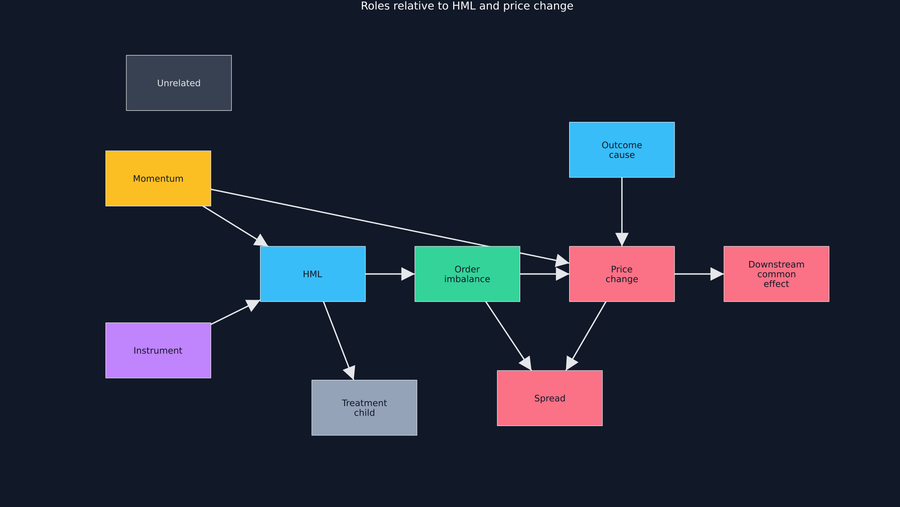

In [1]:
table(values,name,caption) = save_table(values,paths,name;caption,label="tab:chapter23-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
treatment,outcome = "HML","PC"
edges = [("HML","OI"),("OI","PC"),("MOM","HML"),("MOM","PC"),("OI","BAS"),("PC","BAS"),("IV","HML"),("AO","PC"),("PC","DO"),("HML","DT")]
base_graph = DirectedGraph(edges)
finance_graph = DirectedGraph(vcat(base_graph.nodes,"U"),edges)
expected_roles = ["MOM"=>"confounder","OI"=>"mediator","BAS"=>"collider","IV"=>"instrument","AO"=>"ancestor_of_outcome","DO"=>"collider","DT"=>"descendant_of_treatment","U"=>"independent"]
role_rows = Tuple[]
for (variable,expected) in expected_roles
    observed = classify_causal_role(finance_graph,treatment,outcome,variable)
    push!(role_rows,(variable,replace(expected,"_"=>" "),replace(observed,"_"=>" "),observed==expected))
end
role_classification = frame(["Variable","Expected role","Observed role","Matched"],role_rows)
finance_graph_edges = frame(["From","To"],ordered_edges(finance_graph))
role_boolean_checks = frame(["Variable","Confounder","Mediator","Collider","Instrument"],[(variable,is_confounder(finance_graph,treatment,outcome,variable),is_mediator(finance_graph,treatment,outcome,variable),is_collider(finance_graph,treatment,outcome,variable),is_instrument(finance_graph,treatment,outcome,variable)) for (variable,_) in expected_roles])
table(finance_graph_edges,"finance_graph_edges","Directed edges in the Chapter 23 finance graph.")
table(role_classification,"role_classification","Variable roles relative to HML and price change.")
table(role_boolean_checks,"role_boolean_checks","Direct checks of the four central variable roles.")
positions = Dict("MOM"=>(-2.,1.),"IV"=>(-2.,-.8),"U"=>(-1.8,2.),"HML"=>(-.5,0.),"OI"=>(1.,0.),"PC"=>(2.5,0.),"BAS"=>(1.8,-1.3),"AO"=>(2.5,1.3),"DO"=>(4.,0.),"DT"=>(0.,-1.4))
node_colors = merge(Dict(treatment=>palette.cyan,outcome=>palette.rose),Dict(variable=>role_color(role) for (variable,role) in expected_roles))
labels = Dict("HML"=>"HML","OI"=>"Order\nimbalance","PC"=>"Price\nchange","MOM"=>"Momentum","BAS"=>"Spread","IV"=>"Instrument","AO"=>"Outcome\ncause","DO"=>"Downstream\ncommon\neffect","DT"=>"Treatment\nchild","U"=>"Unrelated")
save_figure(plot(graph_panel(finance_graph,positions,"Roles relative to HML and price change";colors=node_colors,labels);size=(1350,760)),paths,"finance_role_graph")


## Ordering causal roles in a graph

Ancestor and descendant sets collect every node connected by a directed path into or out of a chosen node:

$$
\operatorname{An}_G(v)=\{u:u\rightsquigarrow v\},\qquad \operatorname{De}_G(v)=\{u:v\rightsquigarrow u\}.
$$

Here, $v$ is a chosen node, $u$ is another node, $u\rightsquigarrow v$ denotes a directed path from $u$ to $v$, $\operatorname{An}_G(v)$ is the ancestor set, and $\operatorname{De}_G(v)$ is the descendant set.

Row,Variable,Ancestor of treatment,Ancestor of outcome,Descendant of treatment,Descendant of outcome,Role
,String,Bool,Bool,Bool,Bool,String
1,MOM,true,true,false,false,confounder
2,OI,false,true,true,false,mediator
3,BAS,false,false,true,true,collider
4,IV,true,true,false,false,instrument
5,AO,false,true,false,false,ancestor of outcome
6,DO,false,false,true,true,collider
7,DT,false,false,true,false,descendant of treatment
8,U,false,false,false,false,independent


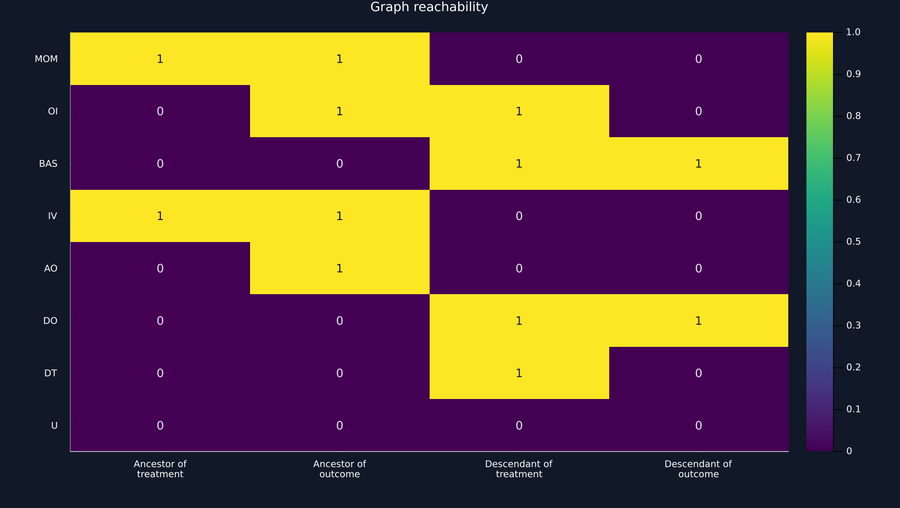

Row,Variable,Paths to treatment,Paths to outcome,Paths from treatment,Paths from outcome,Role
,String,Int64,Int64,Int64,Int64,String
1,MOM,1,2,0,0,confounder
2,OI,0,1,1,0,mediator
3,BAS,0,0,2,1,collider
4,IV,1,1,0,0,instrument
5,AO,0,1,0,0,ancestor of outcome
6,DO,0,0,1,1,collider
7,DT,0,0,1,0,descendant of treatment
8,U,0,0,0,0,independent


In [2]:
ancestor_treatment,ancestor_outcome = reachable(finance_graph,treatment;reverse=true),reachable(finance_graph,outcome;reverse=true)
descendant_treatment,descendant_outcome = reachable(finance_graph,treatment),reachable(finance_graph,outcome)
role_reachability = frame(["Variable","Ancestor of treatment","Ancestor of outcome","Descendant of treatment","Descendant of outcome","Role"],[(variable,variable in ancestor_treatment,variable in ancestor_outcome,variable in descendant_treatment,variable in descendant_outcome,replace(classify_causal_role(finance_graph,treatment,outcome,variable),"_"=>" ")) for (variable,_) in expected_roles])
table(role_reachability,"role_reachability","Reachability facts used by the role classifier.")
reachability_values = Int.(Matrix(role_reachability[:,2:5]))
save_figure(plot(matrix_panel(reachability_values,["Ancestor of\ntreatment","Ancestor of\noutcome","Descendant of\ntreatment","Descendant of\noutcome"],"Graph reachability";rows=role_reachability.Variable,limits=(0,1),colors=:viridis,annotate=true);size=(1150,650),xrotation=0),paths,"role_reachability_matrix")
role_path_witnesses = frame(["Variable","Paths to treatment","Paths to outcome","Paths from treatment","Paths from outcome","Role"],[(variable,length(graph_paths(finance_graph,variable,treatment;directed=true)),length(graph_paths(finance_graph,variable,outcome;directed=true)),length(graph_paths(finance_graph,treatment,variable;directed=true)),length(graph_paths(finance_graph,outcome,variable;directed=true)),replace(classify_causal_role(finance_graph,treatment,outcome,variable),"_"=>" ")) for (variable,_) in expected_roles])
table(role_path_witnesses,"role_path_witnesses","Directed-path counts that witness each role.")


## A Known Finance System

The generated finance system follows the declared graph through one structural equation for each nonroot variable:

$$
\begin{aligned}
H&=0.65M+0.55I+\varepsilon_H,\\
O&=0.80H+\varepsilon_O,\\
P&=0.70O+0.55M+0.40A+\varepsilon_P,\\
B&=0.50O+0.60P+\varepsilon_B.
\end{aligned}
$$

Here, $H$ is HML, $M$ is momentum, $I$ is the instrument, $O$ is order imbalance, $P$ is price change, $A$ is an additional cause of price change, $B$ is the bid-ask spread, and each $\varepsilon$ is an independent standard-normal disturbance.

Row,Child,Parent,Coefficient
,String,String,Float64
1,HML,Momentum,0.65
2,HML,Instrument,0.55
3,Order imbalance,HML,0.8
4,Price change,Order imbalance,0.7
5,Price change,Momentum,0.55
6,Price change,Outcome cause,0.4
7,Spread,Order imbalance,0.5
8,Spread,Price change,0.6


Row,Variable,Observations,Mean,Standard deviation
,String,Int64,Float64,Float64
1,HML,50000,-0.00598036,1.31637
2,OI,50000,0.00211272,1.44945
3,PC,50000,0.00946488,1.71005
4,MOM,50000,0.00202406,0.994165
5,BAS,50000,0.0130401,1.90962
6,IV,50000,-0.00134017,0.999313
7,AO,50000,0.00472568,1.00431
8,DO,50000,-0.00218466,1.31433
9,DT,50000,0.000383021,1.27538


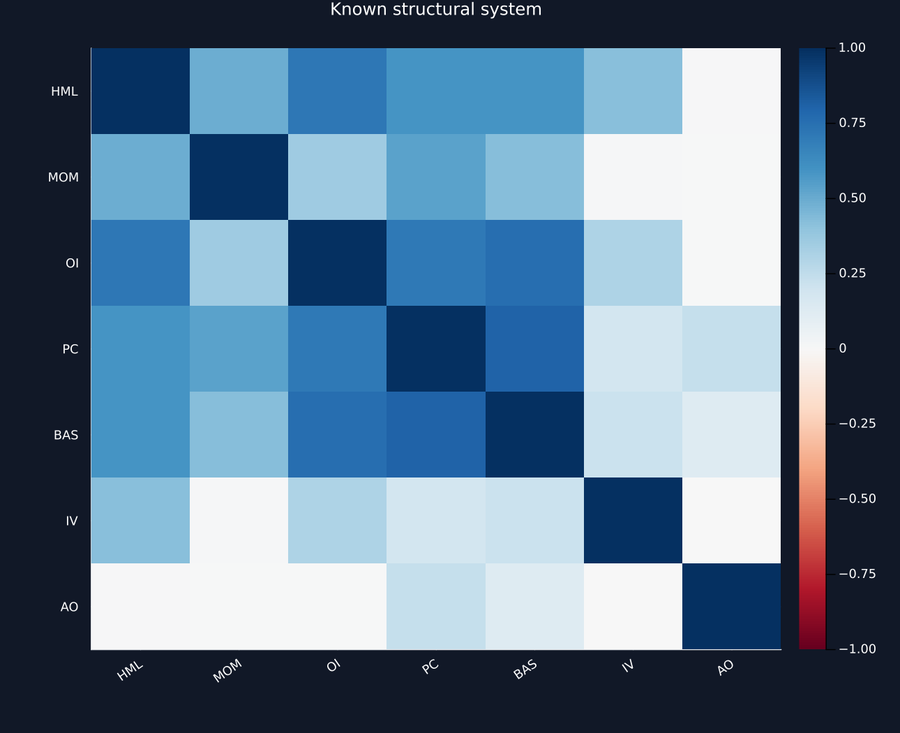

In [3]:
generated_size = 50000
innovations = primitive_input(input_directory,2302)
momentum,instrument,outcome_cause,unrelated = eachcol(innovations[:,1:4])
hml = .65momentum+.55instrument+innovations[:,5]
order_imbalance = .8hml+innovations[:,6]
price_change = .7order_imbalance+.55momentum+.4outcome_cause+innovations[:,7]
spread = .5order_imbalance+.6price_change+innovations[:,8]
treatment_child,outcome_child = .6hml+innovations[:,9],.5price_change+innovations[:,10]
generated_finance = DataFrame(HML=hml,OI=order_imbalance,PC=price_change,MOM=momentum,BAS=spread,IV=instrument,AO=outcome_cause,DO=outcome_child,DT=treatment_child,U=unrelated)
finance_structural_parameters = frame(["Child","Parent","Coefficient"],[["HML","Momentum",0.65],["HML","Instrument",0.55],["Order imbalance","HML",0.8],["Price change","Order imbalance",0.7],["Price change","Momentum",0.55],["Price change","Outcome cause",0.4],["Spread","Order imbalance",0.5],["Spread","Price change",0.6]])
generated_data_summary = DataFrame("Variable"=>names(generated_finance),"Observations"=>fill(generated_size,10),"Mean"=>mean.(eachcol(generated_finance)),"Standard deviation"=>std.(eachcol(generated_finance)))
table(finance_structural_parameters,"finance_structural_parameters","Coefficients in the known finance system.")
table(generated_data_summary,"generated_data_summary","Generated observations from the declared finance graph.")
core_variables = ["HML","MOM","OI","PC","BAS","IV","AO"]
core_correlation = cor(Matrix(generated_finance[:,core_variables]))
save_data(generated_finance,paths,"generated_finance")
save_data(matrix_data(core_correlation),paths,"finance_core_correlation")
save_figure(plot(matrix_panel(core_correlation,core_variables,"Known structural system");size=(860,700)),paths,"finance_structural_correlations")


## Conditioning Changes the Question

A linear coefficient for the treatment is obtained by projecting the outcome on the treatment and the chosen control set:

$$
\widehat\beta_X(C)=e_X^{\mathsf T}(D_C^{\mathsf T}D_C)^{-1}D_C^{\mathsf T}Y.
$$

Here, $C$ is the control set, $D_C$ contains an intercept, the treatment $X$, and the controls in $C$, $Y$ is the outcome vector, $e_X$ selects the treatment coordinate, and $\widehat\beta_X(C)$ is the fitted treatment coefficient under that particular choice of controls.

Row,Specification,Controls,HML coefficient,Distance from total effect,R squared
,String,String,Float64,Float64,Float64
1,No controls,None,0.771673,0.211673,0.352862
2,Confounder,MOM,0.561177,0.00117696,0.433288
3,Confounder and outcome cause,"MOM, AO",0.559406,-0.000593985,0.488608
4,Confounder and mediator,"MOM, OI",-0.00460774,-0.564608,0.603739
5,Confounder and collider,"MOM, BAS",0.125718,-0.434282,0.707089
6,Confounder and unrelated,"MOM, U",0.561182,0.00118152,0.43329


Row,Quantity,Value
,String,Float64
1,Known indirect HML effect,0.56
2,Generated observations,50000.0
3,Disturbance variance,1.0
4,Confounder coefficient into HML,0.65
5,Confounder coefficient into price change,0.55


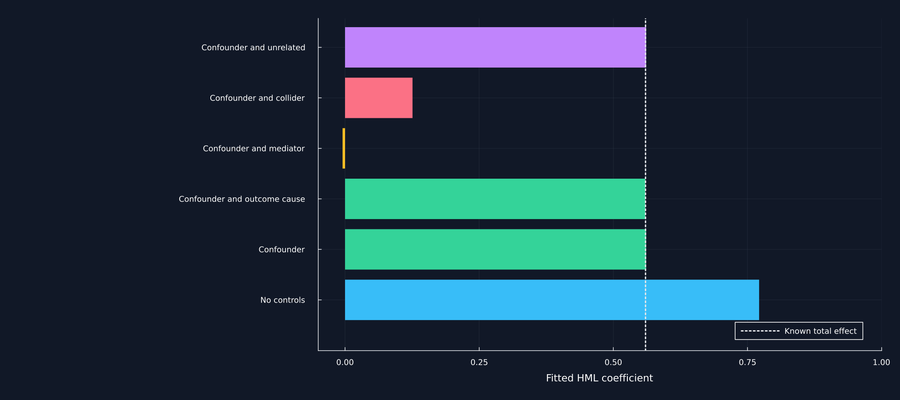

In [4]:
control_sets = ["No controls"=>String[],"Confounder"=>["MOM"],"Confounder and outcome cause"=>["MOM","AO"],"Confounder and mediator"=>["MOM","OI"],"Confounder and collider"=>["MOM","BAS"],"Confounder and unrelated"=>["MOM","U"]]
total_effect = .8*.7
adjustment_rows = Tuple[]
for (name,controls) in control_sets
    coefficient,r_squared = regression_summary(generated_finance,"PC","HML",controls)
    push!(adjustment_rows,(name,isempty(controls) ? "None" : join(controls,", "),coefficient,coefficient-total_effect,r_squared))
end
conditioning_comparison = frame(["Specification","Controls","HML coefficient","Distance from total effect","R squared"],adjustment_rows)
role_regression_truth = DataFrame("Quantity"=>["Known indirect HML effect","Generated observations","Disturbance variance","Confounder coefficient into HML","Confounder coefficient into price change"],"Value"=>[total_effect,generated_size,1.,.65,.55])
table(conditioning_comparison,"conditioning_comparison","Treatment coefficients under different conditioning choices.")
table(role_regression_truth,"role_regression_truth","Known quantities in the finance system.")
figure = bar(1:6,conditioning_comparison[!,"HML coefficient"];orientation=:horizontal,color=[palette.cyan,palette.green,palette.green,palette.amber,palette.rose,violet],linealpha=0,yticks=(1:6,conditioning_comparison.Specification),xlims=(-.05,1),xlabel="Fitted HML coefficient",label="",left_margin=67Plots.mm,legend=:bottomright,size=(1350,600))
vline!(figure,[total_effect];color=palette.text,linestyle=:dot,label="Known total effect")
save_figure(figure,paths,"conditioning_coefficient_comparison")


## Instrument Role

In the declared graph, an instrument reaches the outcome only through the treatment and has no open path to the outcome after the treatment link is removed:

$$
I\rightsquigarrow X,\qquad I\rightsquigarrow Y\Rightarrow X\in\pi_{IY},\qquad I\perp_G Y\mid\operatorname{do}(X\leftarrow\varnothing).
$$

Here, $I$ is the proposed instrument, $X$ is the treatment, $Y$ is the outcome, $\pi_{IY}$ is any directed path from $I$ to $Y$, and $\operatorname{do}(X\leftarrow\varnothing)$ denotes removing arrows into the treatment for this graphical check.

Row,Condition,Result
,String,Bool
1,Instrument reaches treatment,true
2,Every directed instrument-outcome path passes through treatment,true
3,No instrument-outcome path remains after removing treatment,true
4,Released classifier labels instrument,true


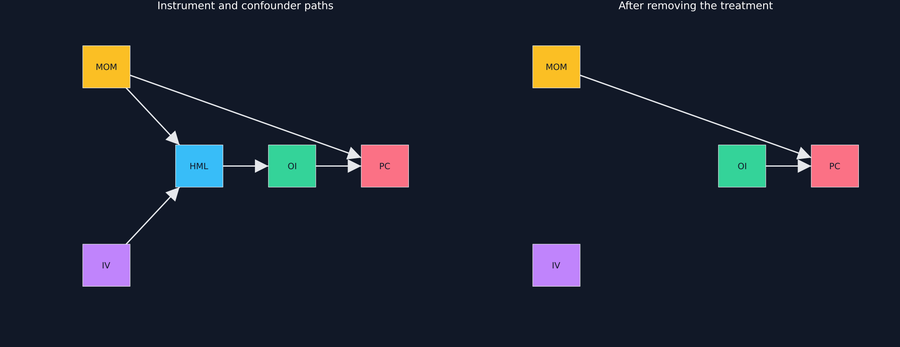

Row,Quantity,Value
,String,Int64
1,Graph nodes,10
2,Directed edges,10
3,Classified variables,8
4,Matched role checks,8
5,Generated observations,50000
6,Conditioning choices,6
7,Instrument checks,4
8,Figures,5
9,Generated tables,10


In [5]:
directed_instrument_paths = graph_paths(finance_graph,"IV",outcome;directed=true)
graph_without_treatment = subgraph(finance_graph,filter(!=(treatment),finance_graph.nodes))
instrument_conditions = DataFrame("Condition"=>["Instrument reaches treatment","Every directed instrument-outcome path passes through treatment","No instrument-outcome path remains after removing treatment","Released classifier labels instrument"],"Result"=>[treatment in reachable(finance_graph,"IV"),all(path->treatment in path,directed_instrument_paths),!(outcome in reachable(graph_without_treatment,"IV")),classify_causal_role(finance_graph,treatment,outcome,"IV")=="instrument"])
table(instrument_conditions,"instrument_conditions","Graph checks for the proposed instrument.")
instrument_graph = subgraph(finance_graph,["IV","MOM","HML","OI","PC"])
instrument_positions = Dict("IV"=>(-2.,-.8),"MOM"=>(-2.,.8),"HML"=>(-.5,0.),"OI"=>(1.,0.),"PC"=>(2.5,0.))
removed_graph = subgraph(instrument_graph,filter(!=("HML"),instrument_graph.nodes))
save_figure(plot(graph_panel(instrument_graph,instrument_positions,"Instrument and confounder paths";colors=node_colors),graph_panel(removed_graph,instrument_positions,"After removing the treatment";colors=node_colors);layout=(1,2),size=(1400,540)),paths,"instrument_role_paths")
role_section_summary = DataFrame("Quantity"=>["Graph nodes","Directed edges","Classified variables","Matched role checks","Generated observations","Conditioning choices","Instrument checks","Figures","Generated tables"],"Value"=>[length(finance_graph.nodes),length(finance_graph.edges),nrow(role_classification),count(role_classification.Matched),generated_size,nrow(conditioning_comparison),nrow(instrument_conditions),5,10])
table(role_section_summary,"role_section_summary","Section 23.2 numerical summary.")


## Tests

In [6]:
@assert acyclic(finance_graph)
@assert all(role_classification.Matched)
@assert role_boolean_checks[1,"Confounder"]
@assert role_boolean_checks[2,"Mediator"]
@assert role_boolean_checks[3,"Collider"]
@assert role_boolean_checks[4,"Instrument"]
@assert nrow(role_reachability)==8
@assert nrow(role_path_witnesses)==8
@assert size(generated_finance)==(50000,10)
@assert all(isfinite,Matrix(generated_finance))
@assert total_effect≈.56
@assert abs(conditioning_comparison[3,"HML coefficient"]-total_effect)<.03
@assert abs(conditioning_comparison[4,"HML coefficient"])<.03
@assert abs(conditioning_comparison[5,"Distance from total effect"])>.05
@assert all(instrument_conditions.Result)
@assert nrow(role_section_summary)==9
assert_artifacts(["finance_role_graph","role_reachability_matrix","finance_structural_correlations","conditioning_coefficient_comparison","instrument_role_paths"],["finance_graph_edges","role_classification","role_boolean_checks","role_reachability","role_path_witnesses","finance_structural_parameters","generated_data_summary","conditioning_comparison","role_regression_truth","instrument_conditions","role_section_summary"])
nothing
